To correct for FDR across 5 immunosigs and to add CI to regression

# Header

In [1]:
source('functions.R')

Loading required package: SeuratObject

Loading required package: sp


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t



Attaching package: ‘dplyr’


The following object is masked from ‘package:gridExtra’:

    combine


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘anndata’


The following object is masked from ‘package:SeuratObject’:

    Layers




In [2]:
setwd('../')

# Plot

## BC

In [3]:
mg = read.csv('data/09_externalds/23pt_clean/gsva_23pt_IMMPOP.csv', 
              row.names=1, check.names=F)
mg

,Sample,Dataset,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature,IMM-POP Up,IMM-POP Dn
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX8136156,SRX8136156,GSE148892,Whole_blood,GSM4485272,3.915864,3.443940,6.474928,0.6627942,7.487532,2.561433,2.926000
SRX8136157,SRX8136157,GSE148892,Whole_blood,GSM4485273,3.998675,6.074275,5.193996,0.5832359,4.060746,2.315043,2.997988
SRX8136158,SRX8136158,GSE148892,Whole_blood,GSM4485274,6.437120,5.518656,4.352223,0.7701919,2.129005,2.305899,3.113792
SRX8136160,SRX8136160,GSE148892,Whole_blood,GSM4485276,6.628620,2.361768,5.658363,2.9828247,3.310755,2.309404,3.098418
SRX8136161,SRX8136161,GSE148892,Whole_blood,GSM4485277,6.799967,1.674307,5.666059,4.0981414,3.022511,2.228483,3.011304
SRX8136162,SRX8136162,GSE148892,Whole_blood,GSM4485278,2.723668,5.252953,4.100817,2.9339280,5.688330,2.367599,3.163912
SRX8136163,SRX8136163,GSE148892,Whole_blood,GSM4485279,1.874542,5.366436,6.559609,5.1914584,2.409984,2.278372,3.052911
SRX8136165,SRX8136165,GSE148892,Whole_blood,GSM4485281,7.158963,3.215511,4.872542,1.0076999,3.810841,2.323673,3.038132
SRX8136167,SRX8136167,GSE148892,Whole_blood,GSM4485283,2.959670,5.746122,5.848580,4.7556670,2.378611,2.310419,3.069808


In [4]:
mg[['IMM-POP']] = mg[['IMM-POP Up']] - mg[['IMM-POP Dn']]
mg

,Sample,Dataset,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature,IMM-POP Up,IMM-POP Dn,IMM-POP
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX8136156,SRX8136156,GSE148892,Whole_blood,GSM4485272,3.915864,3.443940,6.474928,0.6627942,7.487532,2.561433,2.926000,-0.3645669
SRX8136157,SRX8136157,GSE148892,Whole_blood,GSM4485273,3.998675,6.074275,5.193996,0.5832359,4.060746,2.315043,2.997988,-0.6829450
SRX8136158,SRX8136158,GSE148892,Whole_blood,GSM4485274,6.437120,5.518656,4.352223,0.7701919,2.129005,2.305899,3.113792,-0.8078937
SRX8136160,SRX8136160,GSE148892,Whole_blood,GSM4485276,6.628620,2.361768,5.658363,2.9828247,3.310755,2.309404,3.098418,-0.7890135
SRX8136161,SRX8136161,GSE148892,Whole_blood,GSM4485277,6.799967,1.674307,5.666059,4.0981414,3.022511,2.228483,3.011304,-0.7828205
SRX8136162,SRX8136162,GSE148892,Whole_blood,GSM4485278,2.723668,5.252953,4.100817,2.9339280,5.688330,2.367599,3.163912,-0.7963131
SRX8136163,SRX8136163,GSE148892,Whole_blood,GSM4485279,1.874542,5.366436,6.559609,5.1914584,2.409984,2.278372,3.052911,-0.7745382
SRX8136165,SRX8136165,GSE148892,Whole_blood,GSM4485281,7.158963,3.215511,4.872542,1.0076999,3.810841,2.323673,3.038132,-0.7144591
SRX8136167,SRX8136167,GSE148892,Whole_blood,GSM4485283,2.959670,5.746122,5.848580,4.7556670,2.378611,2.310419,3.069808,-0.7593889



Attaching package: ‘boot’


The following objects are masked from ‘package:gtools’:

    inv.logit, logit


`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


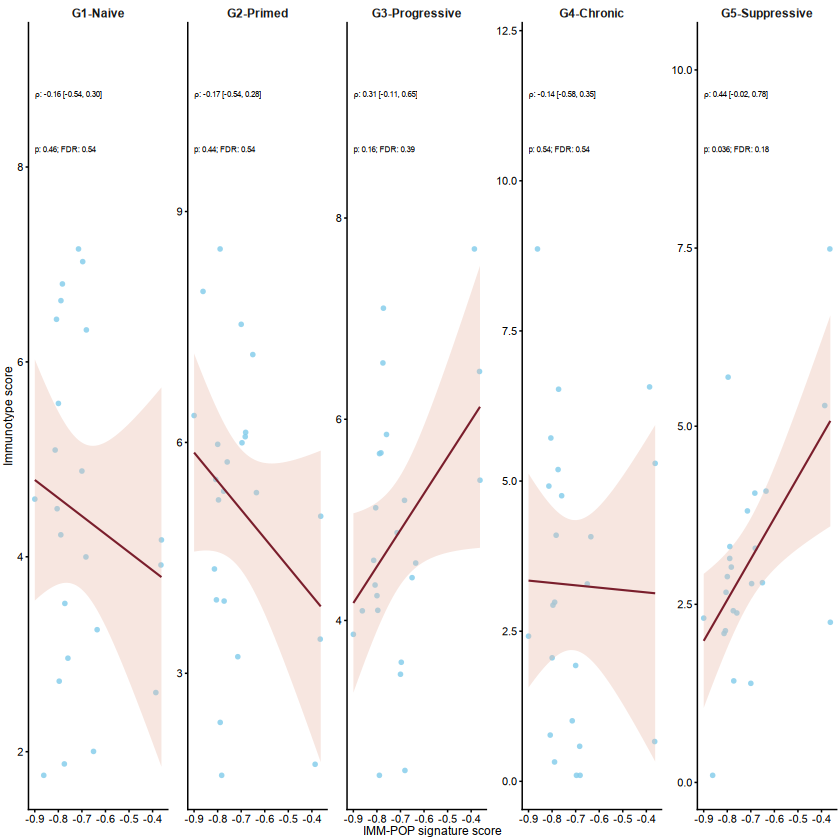

In [5]:
library(dplyr)
library(tidyr)
library(ggplot2)
library(boot)

dir.create("plots/F7", recursive = TRUE, showWarnings = FALSE)

sig_map <- c(
  "G1_signature" = "G1-Naive",
  "G2_signature" = "G2-Primed",
  "G3_signature" = "G3-Progressive",
  "G4_signature" = "G4-Chronic",
  "G5_signature" = "G5-Suppressive"
)

sig_cols <- names(sig_map)

# Long-format data
df_long <- mg %>%
  select(`IMM-POP`, all_of(sig_cols)) %>%
  pivot_longer(
    cols = all_of(sig_cols),
    names_to = "signature",
    values_to = "score"
  ) %>%
  mutate(
    signature_label = factor(sig_map[signature], levels = sig_map)
  ) %>%
  filter(!is.na(`IMM-POP`), !is.na(score))

# Add panel-specific annotation space
df_long <- df_long %>%
  group_by(signature_label) %>%
  mutate(
    y_min_panel = min(score, na.rm = TRUE),
    y_max_panel = max(score, na.rm = TRUE),
    y_pad_panel = 0.30 * (y_max_panel - y_min_panel),
    y_label1 = y_max_panel + y_pad_panel,
    y_label2 = y_max_panel + 0.65 * y_pad_panel
  ) %>%
  ungroup()

# Bootstrap CI for Spearman rho
spearman_boot_ci <- function(dat, idx) {
  d <- dat[idx, ]
  cor(d$x, d$y, method = "spearman", use = "complete.obs")
}

# Correlation statistics
cor_stats <- df_long %>%
  group_by(signature, signature_label) %>%
  group_modify(~ {
    dat <- data.frame(x = .x$`IMM-POP`, y = .x$score)

    ct <- cor.test(dat$x, dat$y, method = "spearman", exact = FALSE)

    set.seed(1)
    bt <- boot(dat, statistic = spearman_boot_ci, R = 2000)
    ci <- boot.ci(bt, type = "perc")$percent[4:5]

    tibble(
      rho = unname(ct$estimate),
      p = ct$p.value,
      ci_low = ci[1],
      ci_high = ci[2]
    )
  }) %>%
  ungroup() %>%
  mutate(
    FDR = p.adjust(p, method = "BH"),
    label_rho = sprintf(
      "paste(rho, \": %.2f [%.2f, %.2f]\")",
      rho, ci_low, ci_high
    ),
    label_p = sprintf(
      "\"p: %.2g; FDR: %.2g\"",
      p, FDR
    )
  )

# Annotation positions
ann_pos <- df_long %>%
  group_by(signature_label) %>%
  summarise(
    x_label = min(`IMM-POP`, na.rm = TRUE),
    y_label1 = unique(y_label1),
    y_label2 = unique(y_label2),
    .groups = "drop"
  )

cor_stats <- cor_stats %>%
  left_join(ann_pos, by = "signature_label")

# Plot
p <- ggplot(df_long, aes(x = `IMM-POP`, y = score)) +
  geom_point(
    shape = 16,
    size = 1.1,
    alpha = 0.85,
    color = "skyblue"
  ) +
  geom_smooth(
    method = "lm",
    se = TRUE,
    linewidth = 0.45,
    color = "#7A1E2C",
    fill = "#E8B9A8",
    alpha = 0.35
  ) +
  geom_text(
    data = cor_stats,
    aes(x = x_label, y = y_label1, label = label_rho),
    inherit.aes = FALSE,
    hjust = 0,
    vjust = 1,
    size = 1.55,
    color = "black",
    parse = TRUE
  ) +
  geom_text(
    data = cor_stats,
    aes(x = x_label, y = y_label2, label = label_p),
    inherit.aes = FALSE,
    hjust = 0,
    vjust = 1,
    size = 1.55,
    color = "black",
    parse = TRUE
  ) +
  facet_wrap(~ signature_label, nrow = 1, scales = "free_y") +
  scale_y_continuous(expand = expansion(mult = c(0.05, 0.10))) +
  coord_cartesian(clip = "off") +
  labs(
    x = "IMM-POP signature score",
    y = "Immunotype score"
  ) +
  theme_classic(base_size = 7) +
  theme(
    strip.background = element_blank(),
    strip.text = element_text(size = 7, face = "bold"),
    axis.text = element_text(size = 6),
    axis.title = element_text(size = 7),
    panel.spacing.x = unit(0.35, "lines"),
    plot.margin = margin(2, 2, 2, 2)
  )

fname <- "plots/F7/BC_corr_CI.pdf"

ggsave(
  filename = fname,
  plot = p,
  width = 6,
  height = 1.45,
  units = "in",
  device = "pdf"
)

p

## Total

In [6]:
mg = read.csv('data/09_externalds/18k_clean/gsva_160pt_IMMPOP.csv', 
              row.names=1, check.names=F)
mg

,Sample,Dataset,Diagnosis,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature,IMM-POP Up,IMM-POP Dn
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX3146378,SRX3146378,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760044,5.707469,1.934101,9.561733,5.2320930,0.8826712,0.6740312,0.8889813
SRX3146379,SRX3146379,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760045,6.040090,2.707472,4.838370,6.6767854,1.8362929,0.6324605,0.8166914
SRX3146380,SRX3146380,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760046,5.281971,5.016304,5.908280,3.5297707,1.1403813,0.5437093,0.7841627
SRX3146381,SRX3146381,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760047,3.518146,2.653013,6.720693,5.4872123,4.3834094,0.7364060,0.8006762
SRX3146382,SRX3146382,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760048,4.987088,6.501059,2.738035,2.2148570,2.7959626,0.5365945,0.8075381
SRX3146383,SRX3146383,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760049,2.758298,7.286711,4.350535,5.8176612,0.1000000,0.7310478,0.9076275
SRX3146384,SRX3146384,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760050,5.710118,2.411157,7.111270,4.1996426,2.4436346,0.8544710,0.6858796
SRX3146385,SRX3146385,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760051,5.346418,2.881061,5.329568,5.2533747,2.4113092,0.5140477,0.7193673
SRX3146386,SRX3146386,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760052,4.592317,2.259724,7.732459,3.8073111,4.4530452,0.7558545,0.7427886


In [7]:
mg[['IMM-POP']] = mg[['IMM-POP Up']] - mg[['IMM-POP Dn']]
mg

,Sample,Dataset,Diagnosis,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature,IMM-POP Up,IMM-POP Dn,IMM-POP
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX3146378,SRX3146378,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760044,5.707469,1.934101,9.561733,5.2320930,0.8826712,0.6740312,0.8889813,-0.21495012
SRX3146379,SRX3146379,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760045,6.040090,2.707472,4.838370,6.6767854,1.8362929,0.6324605,0.8166914,-0.18423095
SRX3146380,SRX3146380,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760046,5.281971,5.016304,5.908280,3.5297707,1.1403813,0.5437093,0.7841627,-0.24045331
SRX3146381,SRX3146381,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760047,3.518146,2.653013,6.720693,5.4872123,4.3834094,0.7364060,0.8006762,-0.06427023
SRX3146382,SRX3146382,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760048,4.987088,6.501059,2.738035,2.2148570,2.7959626,0.5365945,0.8075381,-0.27094360
SRX3146383,SRX3146383,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760049,2.758298,7.286711,4.350535,5.8176612,0.1000000,0.7310478,0.9076275,-0.17657969
SRX3146384,SRX3146384,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760050,5.710118,2.411157,7.111270,4.1996426,2.4436346,0.8544710,0.6858796,0.16859139
SRX3146385,SRX3146385,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760051,5.346418,2.881061,5.329568,5.2533747,2.4113092,0.5140477,0.7193673,-0.20531959
SRX3146386,SRX3146386,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760052,4.592317,2.259724,7.732459,3.8073111,4.4530452,0.7558545,0.7427886,0.01306588


`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


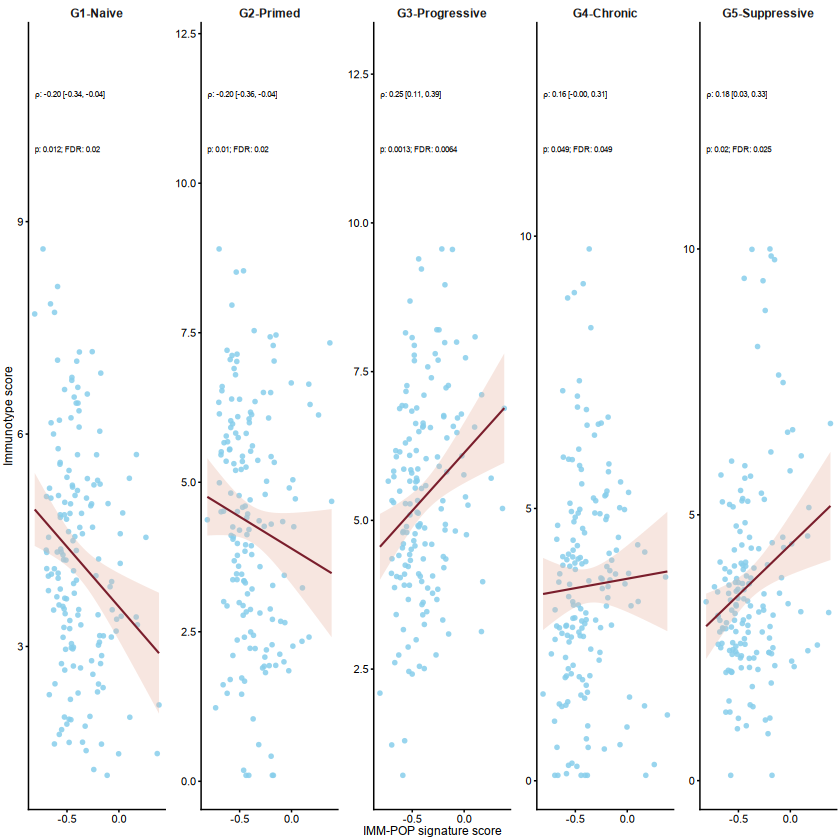

In [8]:
library(dplyr)
library(tidyr)
library(ggplot2)
library(boot)

dir.create("plots/F7", recursive = TRUE, showWarnings = FALSE)

sig_map <- c(
  "G1_signature" = "G1-Naive",
  "G2_signature" = "G2-Primed",
  "G3_signature" = "G3-Progressive",
  "G4_signature" = "G4-Chronic",
  "G5_signature" = "G5-Suppressive"
)

sig_cols <- names(sig_map)

# Long-format data
df_long <- mg %>%
  select(`IMM-POP`, all_of(sig_cols)) %>%
  pivot_longer(
    cols = all_of(sig_cols),
    names_to = "signature",
    values_to = "score"
  ) %>%
  mutate(
    signature_label = factor(sig_map[signature], levels = sig_map)
  ) %>%
  filter(!is.na(`IMM-POP`), !is.na(score))

# Add panel-specific annotation space
df_long <- df_long %>%
  group_by(signature_label) %>%
  mutate(
    y_min_panel = min(score, na.rm = TRUE),
    y_max_panel = max(score, na.rm = TRUE),
    y_pad_panel = 0.30 * (y_max_panel - y_min_panel),
    y_label1 = y_max_panel + y_pad_panel,
    y_label2 = y_max_panel + 0.65 * y_pad_panel
  ) %>%
  ungroup()

# Bootstrap CI for Spearman rho
spearman_boot_ci <- function(dat, idx) {
  d <- dat[idx, ]
  cor(d$x, d$y, method = "spearman", use = "complete.obs")
}

# Correlation statistics
cor_stats <- df_long %>%
  group_by(signature, signature_label) %>%
  group_modify(~ {
    dat <- data.frame(x = .x$`IMM-POP`, y = .x$score)

    ct <- cor.test(dat$x, dat$y, method = "spearman", exact = FALSE)

    set.seed(1)
    bt <- boot(dat, statistic = spearman_boot_ci, R = 2000)
    ci <- boot.ci(bt, type = "perc")$percent[4:5]

    tibble(
      rho = unname(ct$estimate),
      p = ct$p.value,
      ci_low = ci[1],
      ci_high = ci[2]
    )
  }) %>%
  ungroup() %>%
  mutate(
    FDR = p.adjust(p, method = "BH"),
    label_rho = sprintf(
      "paste(rho, \": %.2f [%.2f, %.2f]\")",
      rho, ci_low, ci_high
    ),
    label_p = sprintf(
      "\"p: %.2g; FDR: %.2g\"",
      p, FDR
    )
  )

# Annotation positions
ann_pos <- df_long %>%
  group_by(signature_label) %>%
  summarise(
    x_label = min(`IMM-POP`, na.rm = TRUE),
    y_label1 = unique(y_label1),
    y_label2 = unique(y_label2),
    .groups = "drop"
  )

cor_stats <- cor_stats %>%
  left_join(ann_pos, by = "signature_label")

# Plot
p <- ggplot(df_long, aes(x = `IMM-POP`, y = score)) +
  geom_point(
    shape = 16,
    size = 1.1,
    alpha = 0.85,
    color = "skyblue"
  ) +
  geom_smooth(
    method = "lm",
    se = TRUE,
    linewidth = 0.45,
    color = "#7A1E2C",
    fill = "#E8B9A8",
    alpha = 0.35
  ) +
  geom_text(
    data = cor_stats,
    aes(x = x_label, y = y_label1, label = label_rho),
    inherit.aes = FALSE,
    hjust = 0,
    vjust = 1,
    size = 1.55,
    color = "black",
    parse = TRUE
  ) +
  geom_text(
    data = cor_stats,
    aes(x = x_label, y = y_label2, label = label_p),
    inherit.aes = FALSE,
    hjust = 0,
    vjust = 1,
    size = 1.55,
    color = "black",
    parse = TRUE
  ) +
  facet_wrap(~ signature_label, nrow = 1, scales = "free_y") +
  scale_y_continuous(expand = expansion(mult = c(0.05, 0.10))) +
  coord_cartesian(clip = "off") +
  labs(
    x = "IMM-POP signature score",
    y = "Immunotype score"
  ) +
  theme_classic(base_size = 7) +
  theme(
    strip.background = element_blank(),
    strip.text = element_text(size = 7, face = "bold"),
    axis.text = element_text(size = 6),
    axis.title = element_text(size = 7),
    panel.spacing.x = unit(0.35, "lines"),
    plot.margin = margin(2, 2, 2, 2)
  )

fname <- "plots/F7/Total_corr_CI.pdf"

ggsave(
  filename = fname,
  plot = p,
  width = 6,
  height = 1.45,
  units = "in",
  device = "pdf"
)

p